### Imports

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import sympy as sp
from IPython.display import display, Math

### Parâmetros

In [19]:
def queda(CD):                 # queda inicial de Vout por partilha de carga com o CDAC
    return Vref*CDAC/(CD + CDAC)


Vref, CDAC, fclk, err = 1.1, 0.5e-12, 250e6, 5e-4
t1 = 1/fclk                    # 4 ns
Vmin = Vref*(1-err)            # 1.09945 V
gm_ID = 28                     # S/A
dV_max = 50e-3                 # queda máxima em Vout quando liga o CDAC

CD_min = Vref*CDAC/dV_max - CDAC  # CD mínimo para queda <= 50 mV

def Vout(t, gm, CD):
    gds = gm/10
    C = CD + CDAC
    return Vref - Vref*CDAC/C*np.exp(-(gm+gds)*t/(C))

def erro(t, gm, CD):
    gds = gm/10
    C = CD + CDAC
    return Vref*CDAC/C*np.exp(-(gm+gds)*t/C)

def queda(CD):
    return Vref*CDAC/(CD + CDAC)

def gm_necessario(CD, t=t1):
    C = CD + CDAC
    return C/(1.1*t) * np.log(CDAC/(err*C))

### Procura de gm mínimo para C_D

In [20]:
CD_vals = np.arange(1e-12, 20.5e-12, 1e-12)

gm_mins = gm_necessario(CD_vals, t=t1)      # gm mínimo para cada CD
erros   = erro(t1, gm_mins, CD_vals)        # erro aos 4 ns com esse gm
quedas  = queda(CD_vals)                    # queda inicial para cada CD
IDs     = gm_mins / gm_ID                   # corrente com gm/ID = 28

print(f"{'CD [pF]':>8} | {'gm min [mS]':>11} | {'ID [uA]':>7} | {'erro 4ns [mV]':>13} | {'queda [mV]':>10} | {'<=50 mV':>7}")
print("-"*70)
for CD, gm, I, e, q in zip(CD_vals, gm_mins, IDs, erros, quedas):
    print(f"{CD*1e12:8.0f} | {gm*1e3:11.2f} | {I*1e6:7.0f} | {e*1e3:13.3f} | {q*1e3:10.1f} | {'sim' if q <= dV_max else 'não':>7}")


 CD [pF] | gm min [mS] | ID [uA] | erro 4ns [mV] | queda [mV] | <=50 mV
----------------------------------------------------------------------
       1 |        2.22 |      79 |         0.550 |      366.7 |     não
       2 |        3.40 |     122 |         0.550 |      220.0 |     não
       3 |        4.50 |     161 |         0.550 |      157.1 |     não
       4 |        5.53 |     197 |         0.550 |      122.2 |     não
       5 |        6.50 |     232 |         0.550 |      100.0 |     não
       6 |        7.44 |     266 |         0.550 |       84.6 |     não
       7 |        8.34 |     298 |         0.550 |       73.3 |     não
       8 |        9.21 |     329 |         0.550 |       64.7 |     não
       9 |       10.05 |     359 |         0.550 |       57.9 |     não
      10 |       10.87 |     388 |         0.550 |       52.4 |     não
      11 |       11.67 |     417 |         0.550 |       47.8 |     sim
      12 |       12.45 |     445 |         0.550 |       44.0 |  

In [21]:
# VALORES DEFINIDOS
t = t1
gm = 13e-3
Cd = 11e-12
Id = gm / gm_ID

print(f"Período = {t*1e9:.0f} ns")
print(f"gm      = {gm*1e3:.1f} mS")
print(f"Cd      = {Cd*1e12:.0f} pF")
print(f"Vout    = {Vout(t, gm, Cd):.6f} V")
print(f"Erro    = {erro(t, gm, Cd)*1e3:.3f} mV")
print(f"Queda   = {queda(Cd)*1e3:.1f} mV")
print(f"ID      = {Id*1e6:.0f} uA")


Período = 4 ns
gm      = 13.0 mS
Cd      = 11 pF
Vout    = 1.099669 V
Erro    = 0.331 mV
Queda   = 47.8 mV
ID      = 464 uA


### Gráficos

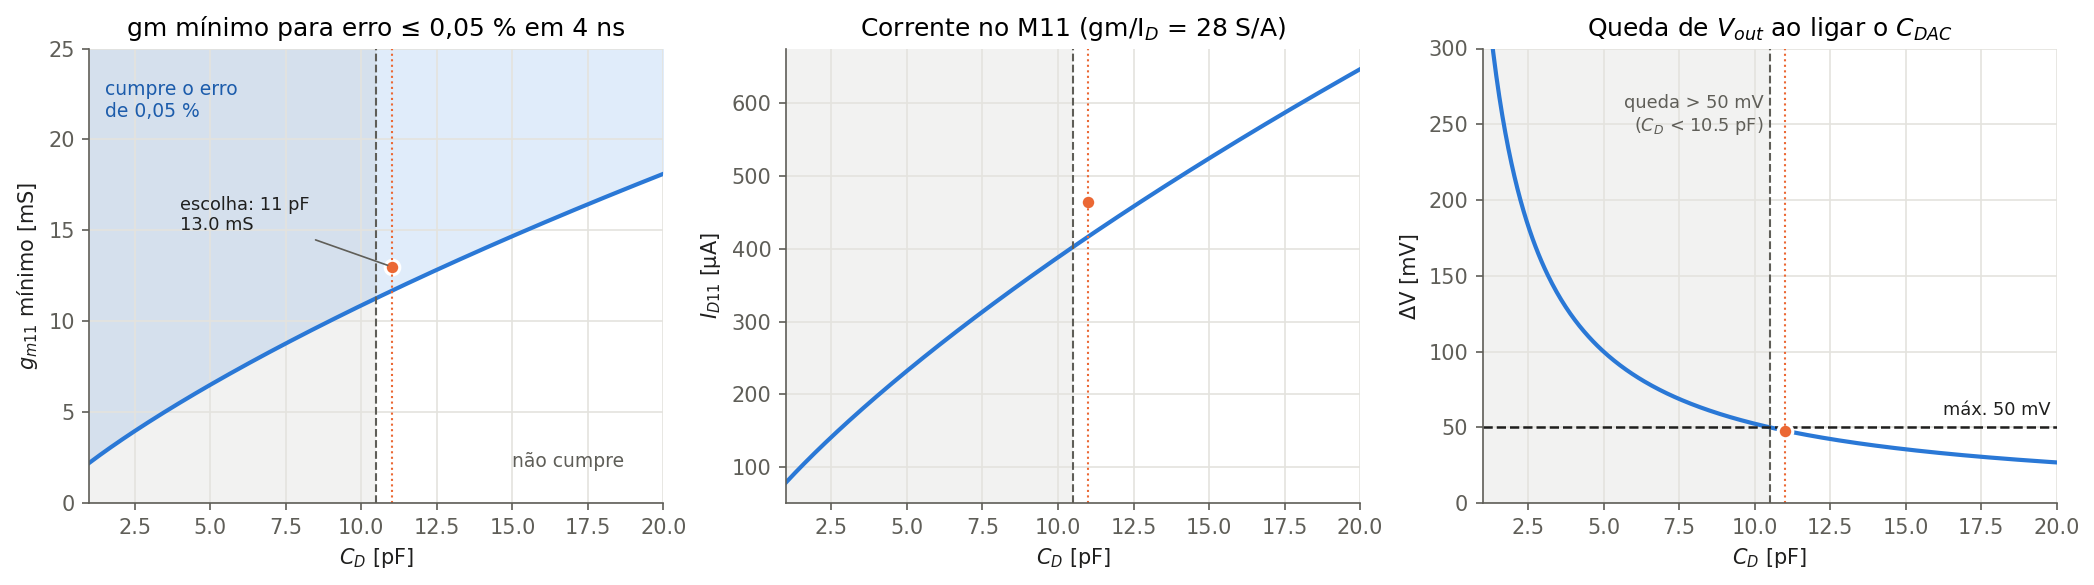

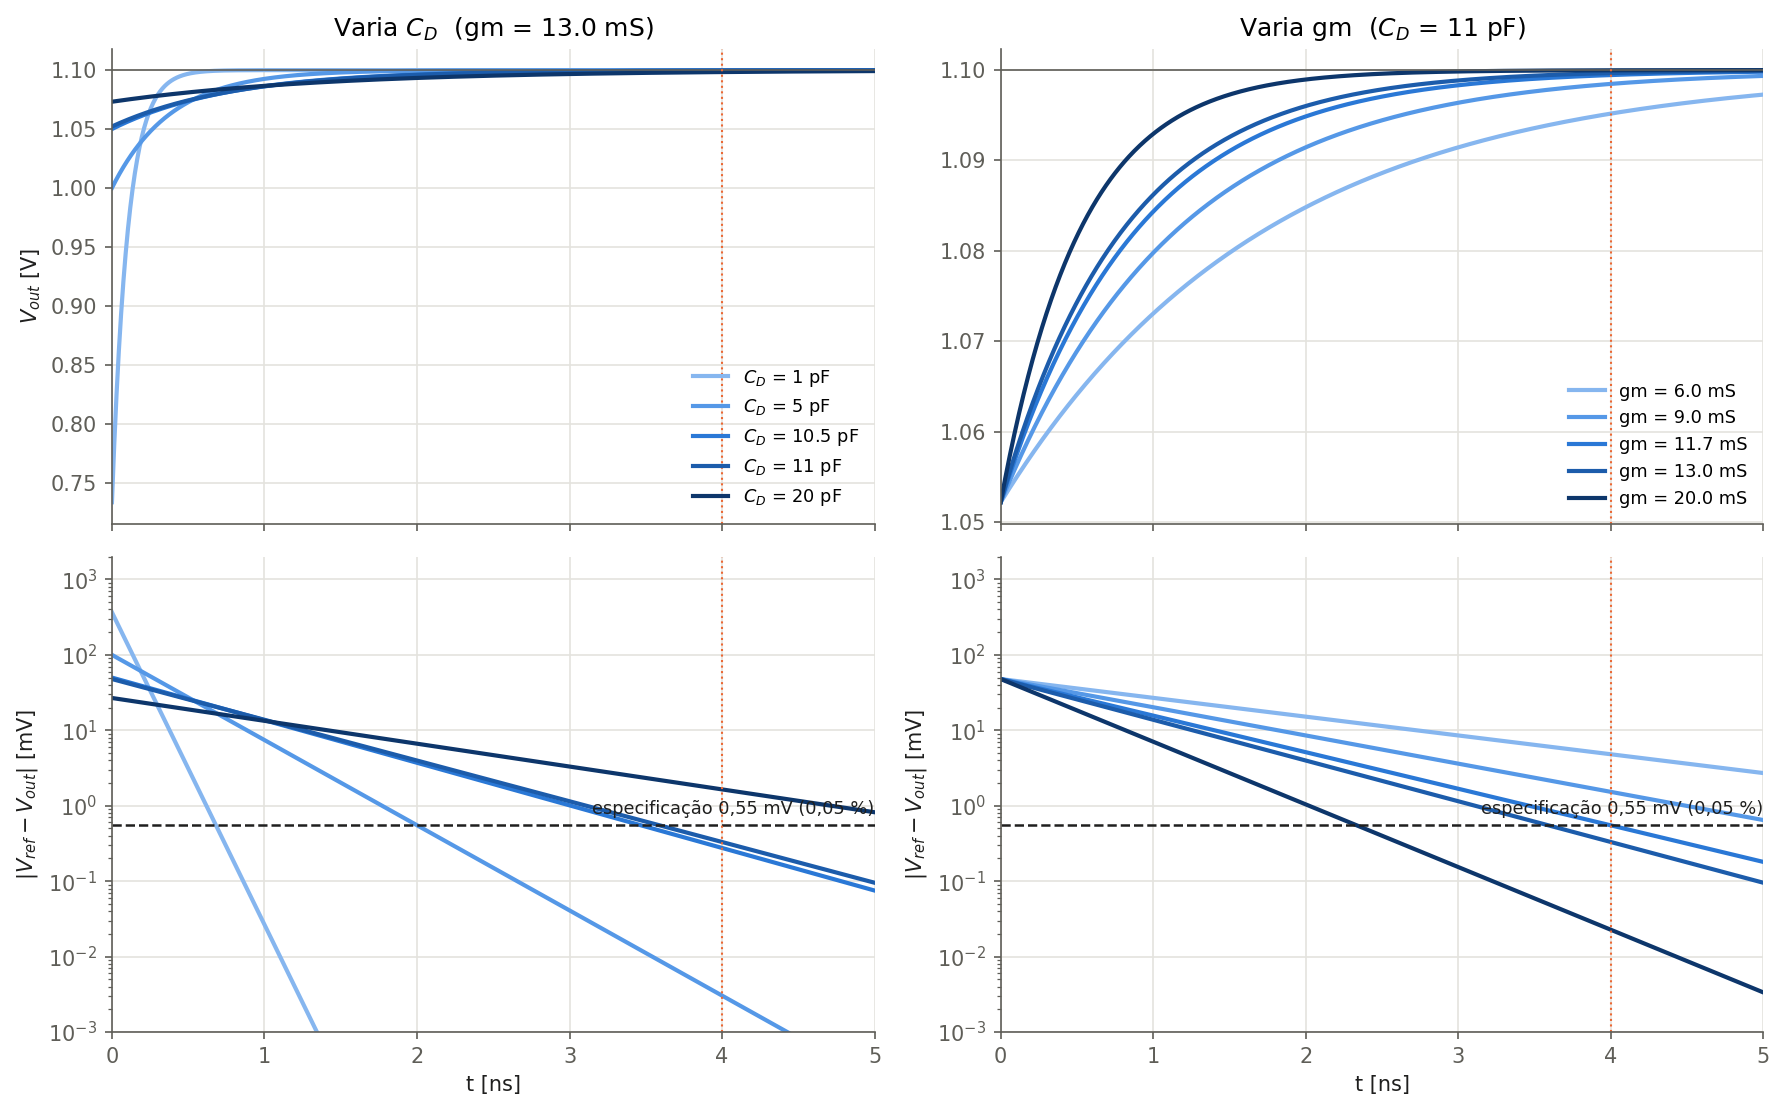

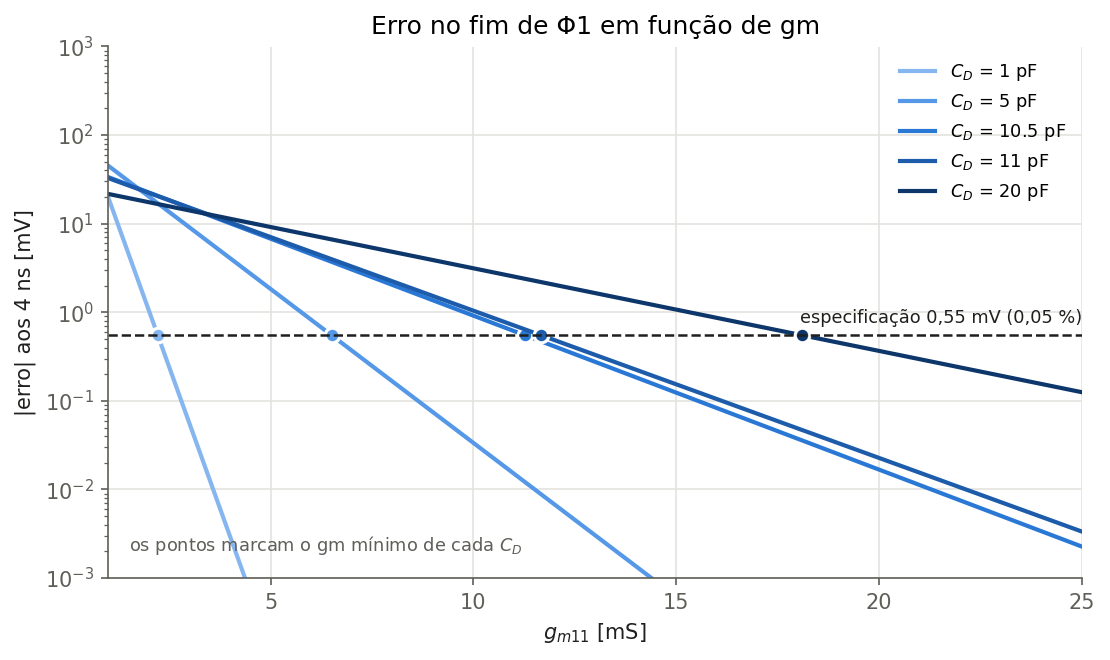

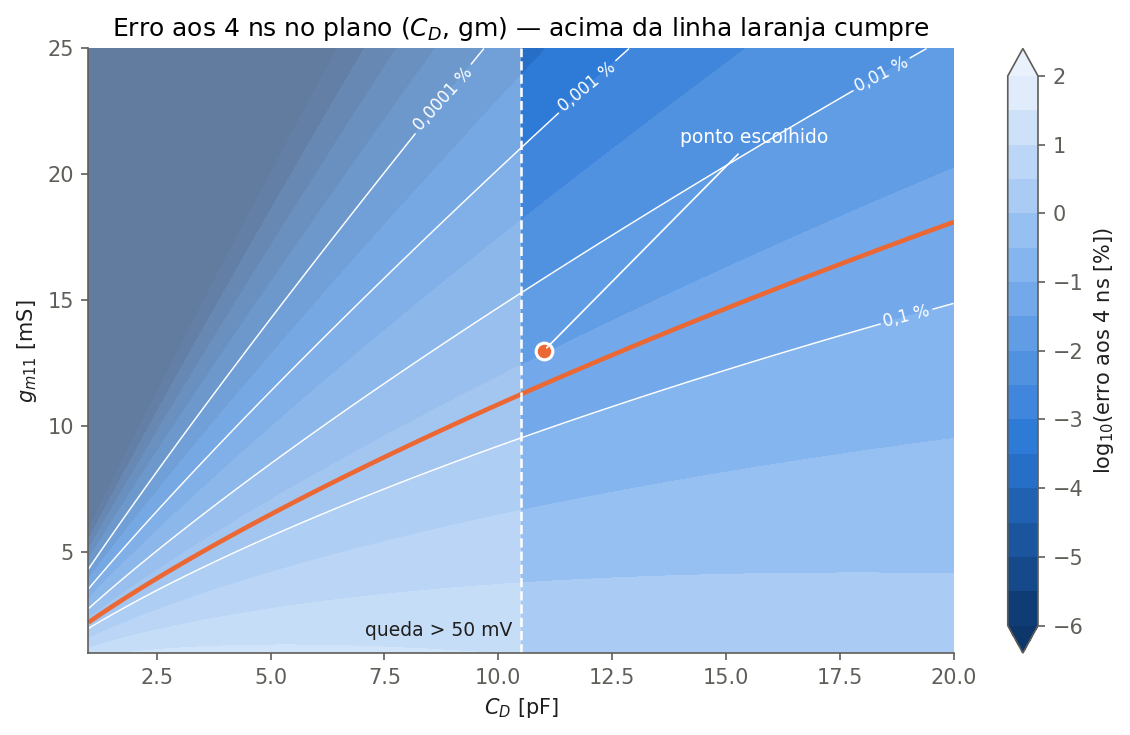

In [22]:
# ======================= GRÁFICOS =======================
# ponto escolhido (nomes próprios para não serem apagados por outros ciclos/arrays)
CD_sel = Cd
gm_sel = gm
 
INK, INK2, GRID = "#1f1f1e", "#5f5e58", "#e4e3de"
RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]   # claro -> escuro
ACC = "#eb6834"                                                  # ponto escolhido
plt.rcParams.update({"font.size": 10, "axes.edgecolor": INK2, "axes.labelcolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "legend.frameon": False, "figure.dpi": 150})
 
T_NS   = t1*1e9                 # 4 ns
Emax   = Vref*err*1e3           # 0.55 mV
CD_MAX = 20e-12                 # eixo de CD: 1 a 20 pF
GM_MAX = 25e-3                  # eixo de gm: até 25 mS
XL = (1, CD_MAX*1e12)
 
def linha_spec(ax):
    ax.axhline(Emax, color=INK, ls="--", lw=1.2)
    ax.text(ax.get_xlim()[1], Emax*1.25, "especificação 0,55 mV (0,05 %)",
            ha="right", va="bottom", color=INK, fontsize=8.5)
def zona_CDmin(ax):             # sombreia CD < CD_min (queda > 50 mV)
    ax.axvspan(ax.get_xlim()[0], CD_min*1e12, color=INK2, alpha=0.08, lw=0)
    ax.axvline(CD_min*1e12, color=INK2, lw=1, ls="--")
 
CDp = np.linspace(1e-12, CD_MAX, 381)
 
# ---- Fig. 1: gm mínimo, corrente e queda em função de C_D ----
gmm = gm_necessario(CDp, t1)
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a in ax: a.set_xlim(*XL)
ax[0].plot(CDp*1e12, gmm*1e3, color=RAMP[2])
ax[0].fill_between(CDp*1e12, gmm*1e3, GM_MAX*1e3, color=RAMP[0], alpha=0.25, lw=0)
ax[0].text(1.5, 0.85*GM_MAX*1e3, "cumpre o erro\nde 0,05 %", color=RAMP[3], fontsize=9)
ax[0].text(15, 2, "não cumpre", color=INK2, fontsize=9)
ax[0].plot(CD_sel*1e12, gm_sel*1e3, "o", color=ACC, ms=7, mec="white", mew=1.5)
ax[0].annotate(f"escolha: {CD_sel*1e12:g} pF\n{gm_sel*1e3:.1f} mS", (CD_sel*1e12, gm_sel*1e3),
               (4, 0.6*GM_MAX*1e3), color=INK, fontsize=8.5,
               arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
ax[0].set(xlabel="$C_D$ [pF]", ylabel="$g_{m11}$ mínimo [mS]", ylim=(0, GM_MAX*1e3),
          title=f"gm mínimo para erro ≤ 0,05 % em {T_NS:g} ns")
ax[1].plot(CDp*1e12, gmm/gm_ID*1e6, color=RAMP[2])
ax[1].plot(CD_sel*1e12, gm_sel/gm_ID*1e6, "o", color=ACC, ms=7, mec="white", mew=1.5)
ax[1].set(xlabel="$C_D$ [pF]", ylabel="$I_{D11}$ [µA]",
          title=f"Corrente no M11 (gm/I$_D$ = {gm_ID} S/A)")
ax[2].plot(CDp*1e12, queda(CDp)*1e3, color=RAMP[2])
ax[2].axhline(dV_max*1e3, color=INK, ls="--", lw=1.2)
ax[2].text(XL[1]-0.2, dV_max*1e3+8, "máx. 50 mV", ha="right", color=INK, fontsize=8.5)
ax[2].plot(CD_sel*1e12, queda(CD_sel)*1e3, "o", color=ACC, ms=7, mec="white", mew=1.5)
ax[2].set(xlabel="$C_D$ [pF]", ylabel="ΔV [mV]", ylim=(0, 300),
          title="Queda de $V_{out}$ ao ligar o $C_{DAC}$")
for a in ax:
    zona_CDmin(a)
    a.axvline(CD_sel*1e12, color=ACC, lw=1, ls=":")
ax[2].text(CD_min*1e12-0.2, 270, f"queda > 50 mV\n($C_D$ < {CD_min*1e12:.1f} pF)",
           ha="right", va="top", color=INK2, fontsize=8.5)
plt.tight_layout(); plt.savefig("fig1_gm_vs_CD.png")
 
# ---- Fig. 2: Vout(t) e erro(t) — varia C_D | varia gm ----
t_ax = np.linspace(0, 1.25*t1, 1000)
CD_list = [1e-12, 5e-12, CD_min, CD_sel, 20e-12]
gm_list = [6e-3, 9e-3, gm_necessario(CD_sel, t1), gm_sel, 20e-3]
fig, ax = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True)
for i, c in enumerate(CD_list):
    ax[0,0].plot(t_ax*1e9, Vout(t_ax, gm_sel, c), color=RAMP[i], label=f"$C_D$ = {c*1e12:g} pF")
    ax[1,0].semilogy(t_ax*1e9, erro(t_ax, gm_sel, c)*1e3, color=RAMP[i])
for i, g in enumerate(gm_list):
    ax[0,1].plot(t_ax*1e9, Vout(t_ax, g, CD_sel), color=RAMP[i], label=f"gm = {g*1e3:.1f} mS")
    ax[1,1].semilogy(t_ax*1e9, erro(t_ax, g, CD_sel)*1e3, color=RAMP[i])
ax[0,0].set(title=f"Varia $C_D$  (gm = {gm_sel*1e3:.1f} mS)", ylabel="$V_{out}$ [V]")
ax[0,1].set(title=f"Varia gm  ($C_D$ = {CD_sel*1e12:g} pF)")
for a in ax[0]:
    a.axhline(Vref, color=INK2, lw=0.8); a.legend(loc="lower right", fontsize=8.5)
for a in ax[1]:
    a.set(xlabel="t [ns]", ylabel="|$V_{ref}-V_{out}$| [mV]", ylim=(1e-3, 2e3), xlim=(0, 1.25*T_NS))
    linha_spec(a)
for a in ax.flat:
    a.axvline(T_NS, color=ACC, lw=1, ls=":")
plt.tight_layout(); plt.savefig("fig2_Vout_t.png")
 
# ---- Fig. 3: erro no fim do período em função de gm, várias C_D ----
gm_ax = np.linspace(1e-3, GM_MAX, 500)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for i, c in enumerate(CD_list):
    ax.semilogy(gm_ax*1e3, erro(t1, gm_ax, c)*1e3, color=RAMP[i], label=f"$C_D$ = {c*1e12:g} pF")
    ax.plot(gm_necessario(c, t1)*1e3, Emax, "o", color=RAMP[i], ms=7, mec="white", mew=1.5)
ax.set(xlabel="$g_{m11}$ [mS]", ylabel=f"|erro| aos {T_NS:g} ns [mV]",
       xlim=(1, GM_MAX*1e3), ylim=(1e-3, 1e3), title="Erro no fim de Φ1 em função de gm")
linha_spec(ax); ax.legend(loc="upper right", fontsize=8.5)
ax.text(1.5, 2e-3, "os pontos marcam o gm mínimo de cada $C_D$", color=INK2, fontsize=8.5)
plt.tight_layout(); plt.savefig("fig3_erro_vs_gm.png")
 
# ---- Fig. 4: mapa do erro no plano (C_D, gm) ----
X, Y = np.meshgrid(np.linspace(1e-12, CD_MAX, 301), np.linspace(1e-3, GM_MAX, 301))
Z = np.log10(erro(t1, Y, X)/Vref*100)      # log10(erro em %)
cmap = LinearSegmentedColormap.from_list("blues", ["#0d366b", "#2a78d6", "#86b6ef", "#e8f1fc"])
fig, ax = plt.subplots(figsize=(8, 5))
cs = ax.contourf(X*1e12, Y*1e3, Z, levels=np.arange(-6, 2.01, 0.5), cmap=cmap, extend="both")
cl = ax.contour(X*1e12, Y*1e3, Z, levels=[-4, -3, -2, -1], colors="white",
                linewidths=0.7, linestyles="solid")
ax.clabel(cl, fmt={-4: "0,0001 %", -3: "0,001 %", -2: "0,01 %", -1: "0,1 %"}, fontsize=8)
ax.contour(X*1e12, Y*1e3, Z, levels=[np.log10(err*100)], colors=ACC,
           linewidths=2.2, linestyles="solid")
ax.axvspan(1, CD_min*1e12, color="white", alpha=0.35, lw=0)
ax.axvline(CD_min*1e12, color="white", lw=1.2, ls="--")
ax.text(CD_min*1e12-0.2, 1.5, "queda > 50 mV", ha="right", va="bottom", color=INK, fontsize=9)
ax.plot(CD_sel*1e12, gm_sel*1e3, "o", color=ACC, ms=8, mec="white", mew=1.5)
ax.annotate("ponto escolhido", (CD_sel*1e12, gm_sel*1e3), (14, 0.85*GM_MAX*1e3), color="white",
            fontsize=9, arrowprops=dict(arrowstyle="-", color="white", lw=0.8))
fig.colorbar(cs).set_label(f"log$_{{10}}$(erro aos {T_NS:g} ns [%])")
ax.grid(False)
ax.set(xlabel="$C_D$ [pF]", ylabel="$g_{m11}$ [mS]",
       title=f"Erro aos {T_NS:g} ns no plano ($C_D$, gm) — acima da linha laranja cumpre")
plt.tight_layout(); plt.savefig("fig4_mapa_CD_gm.png")
 
plt.show()

### Alínea B) - Função transferência

In [23]:
# ---- símbolos ----
s = sp.symbols('s')
V1, V2, V3, Vo, Vr = sp.symbols('V1 V2 V3 V_outR V_ref')   # Vr (não Vref: Vref = 1.1 V lá em cima)

gm1B, gm2B, gm5, gm1 = sp.symbols('g_m1B g_m2B g_m5 g_m1', positive=True)
gds1B, gds2B, gds3B, gds4, gds5, gds1, gdsIB3 = sp.symbols(
    'g_ds1B g_ds2B g_ds3B g_ds4 g_ds5 g_ds1 g_dsIB3', positive=True)
C1, C2, C3, C4 = sp.symbols('C_1 C_2 C_3 C_4', positive=True)      # capacidades à massa de cada nó
Cgd1B, Cdb2B, Cgd5, Cc, Cgs1 = sp.symbols('C_gd1B C_db2B C_gd5 C_c C_gs1', positive=True)  # flutuantes

# ---- equações nodais (soma das correntes que saem = 0) ----
eqs = [
    gm1B*Vr + V1*gds1B + (V1-V3)*gds2B + gm2B*(-V3)
      + s*(V1*C1 + (V1-Vr)*Cgd1B + (V1-V3)*Cdb2B + (V1-V2)*Cgd5),                    # V1
    gm5*V1 + V2*(gds4+gds5) + s*(V2*C2 + (V2-V1)*Cgd5 + (V2-V3)*Cc + (V2-Vo)*Cgs1),   # V2
    V3*gds3B + (V3-V1)*gds2B - gm2B*(-V3) + s*(V3*C3 + (V3-V1)*Cdb2B + (V3-V2)*Cc),   # V3
    -gm1*(V2-Vo) + Vo*(gds1+gdsIB3) + s*(Vo*C4 + (Vo-V2)*Cgs1),                       # VoutR
]

# ---- resolver (regra de Cramer) ----
Y, rhs = sp.linear_eq_to_matrix(eqs, [V1, V2, V3, Vo])
D = sp.expand(Y.det(method='berkowitz'))
Y4 = Y.copy(); Y4[:, 3] = rhs
N = sp.expand(Y4.det(method='berkowitz') / Vr)
if sp.Poly(D, s).coeff_monomial(1).could_extract_minus_sign():   # termo s^0 positivo
    N, D = -N, -D
H = N / D                                                        # função de transferência

# ---- H(s) completa em fração ----
N_s = sp.collect(N, s)
D_s = sp.collect(D, s)
print("Função Transferência H(s):")
display(Math(r"H(s) = \frac{V_{outR}}{V_{ref}} = \frac{" + sp.latex(N_s) + "}{" + sp.latex(D_s) + "}"))

# ---- explicação do agrupamento das capacidades ----
print("Capacidades à massa de cada nó (em paralelo, logo somam-se — a expressão continua exata):")
display(Math(r"C_1 = C_{db1B} + C_{gd2B} + C_{gs5} \qquad (\text{nó } V_1 = v_x)"))
display(Math(r"C_2 = C_p + C_{db5} + C_{db4} + C_{gd4} + C_{gs11} + C_{gd11} + C_{gd1} \qquad (\text{nó } V_2 = V_{ctr})"))
display(Math(r"C_3 = C_{gs2B} + C_{gd3B} + C_{db3B} \qquad (\text{nó } V_3 = \text{fonte do } M_{2B})"))
display(Math(r"C_4 = C_{db1} + C_{db,IB3} + C_{gs1A} + C_{gd1A} \qquad (\text{nó } V_{outR})"))

print("Capacidades flutuantes (ligam dois nós com sinal — ficam separadas):")
display(Math(r"C_{gd1B}: V_{ref} \leftrightarrow V_1 \qquad C_{db2B}: V_1 \leftrightarrow V_3 \qquad "
             r"C_{gd5}: V_1 \leftrightarrow V_2 \qquad C_c: V_2 \leftrightarrow V_3 \qquad "
             r"C_{gs1}: V_2 \leftrightarrow V_{outR}"))

Função Transferência H(s):


<IPython.core.display.Math object>

Capacidades à massa de cada nó (em paralelo, logo somam-se — a expressão continua exata):


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Capacidades flutuantes (ligam dois nós com sinal — ficam separadas):


<IPython.core.display.Math object>

### Alínea C) - Ganho DC, Polos e Zeros Completos

In [24]:
# ---- ganho DC ----
N0 = sp.expand(N.subs(s, 0))          # numerador em s = 0
D0 = sp.expand(D.subs(s, 0))          # denominador em s = 0
A0 = N0 / D0
print("Ganho DC A0 = H(0):")
display(Math(r"A_0 = H(0) = \frac{" + sp.latex(sp.factor(N0)) + "}{" + sp.latex(sp.factor(D0)) + "}"))

Ganho DC A0 = H(0):


<IPython.core.display.Math object>

In [25]:
# =================  Polos e zeros (simbólicos, exatos) =================
a0, a1, a2, a3, a4 = sp.symbols('a_0 a_1 a_2 a_3 a_4')
b0, b1, b2, b3, b4 = sp.symbols('b_0 b_1 b_2 b_3 b_4')

D_gen = a4*s**4 + a3*s**3 + a2*s**2 + a1*s + a0      # denominador genérico
N_gen = b4*s**4 + b3*s**3 + b2*s**2 + b1*s + b0      # numerador genérico

print("Polos: raízes de D(s) = 0")
for k, p in enumerate(sp.solve(D_gen, s), 1):
    display(Math(rf"p_{k} = " + sp.latex(p)))

print("Zeros: raízes de N(s) = 0")
for k, z in enumerate(sp.solve(N_gen, s), 1):
    display(Math(rf"z_{k} = " + sp.latex(z)))

# ---- coeficientes, com as expressões do circuito ----
Dp, Np = sp.Poly(D, s), sp.Poly(N, s)
print("Coeficientes do denominador:")
for k in range(5):
    display(Math(rf"a_{k} = " + sp.latex(Dp.coeff_monomial(s**k))))
print("Coeficientes do numerador:")
for k in range(5):
    display(Math(rf"b_{k} = " + sp.latex(Np.coeff_monomial(s**k))))

Polos: raízes de D(s) = 0


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

...

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Alínea D) - Função transferência, Ganho DC, Polos e Zeros Simplificado

In [26]:
# ================= Alínea d): modelo simplificado =================
v1, v2, v3 = sp.symbols('v_1 v_2 v_3')
gmA, gmB, gmC = sp.symbols('g_mA g_mB g_mC', positive=True)    # gm1B, gm2B+gmb2B, gm5
g1, g2, g3 = sp.symbols('g_1 g_2 g_3', positive=True)
C1s, C2s, C3s = sp.symbols('C_1 C_2 C_3', positive=True)

eqs_s = [
    gmA*Vr + v1*(g1 + s*C1s) - gmB*v2,                  # v1 (vx)
    v2*(g2 + s*C2s) + s*Cc*(v2 - v3),                   # v2 (fonte do cascode)
    gmC*v1 + v3*(g3 + s*C3s) + s*Cc*(v3 - v2),          # v3 (Vctr ≈ VoutR)
]

Ys, rhs_s = sp.linear_eq_to_matrix(eqs_s, [v1, v2, v3])
Ds = sp.expand(Ys.det())
Ys3 = Ys.copy(); Ys3[:, 2] = rhs_s                      # saída = v3 (3.ª incógnita)
Ns = sp.expand(Ys3.det() / Vr)
if sp.Poly(Ds, s).coeff_monomial(1).could_extract_minus_sign():
    Ns, Ds = -Ns, -Ds

display(Math(r"H(s) \approx \frac{" + sp.latex(sp.collect(Ns, s)) + "}{" + sp.latex(sp.collect(Ds, s)) + "}"))

<IPython.core.display.Math object>

In [31]:
# ================= Ganho DC, GBW, Polos e Zeros =================
gmb2B, Csb2B = sp.symbols('g_mb2B C_sb2B', positive=True)   # M2B com bulk à massa

# capacidades individuais de cada transístor
Cdb1B                    = sp.symbols('C_db1B', positive=True)                 # M1B
Cdb2B, Cgd2B, Cgs2B      = sp.symbols('C_db2B C_gd2B C_gs2B', positive=True)   # M2B
Cgd3B, Cdb3B             = sp.symbols('C_gd3B C_db3B', positive=True)          # M3B
Cdb4, Cgd4               = sp.symbols('C_db4 C_gd4', positive=True)            # M4
Cgs5, Cdb5               = sp.symbols('C_gs5 C_db5', positive=True)            # M5
Cgd1                     = sp.symbols('C_gd1', positive=True)                  # M1 (SF)
Cgs11, Cgd11             = sp.symbols('C_gs11 C_gd11', positive=True)          # M11
Cp                       = sp.symbols('C_p', positive=True)

# o que é cada elemento do modelo simplificado
defs = {
    gmA: gm1B,                                   # 1.º andar
    gmB: gm2B + gmb2B,                           # cascode (com efeito de corpo)
    gmC: gm5,                                    # 2.º andar
    g1: gds1B + gds2B*gds3B/(gm2B + gmb2B),      # v1 = vx
    g2: gm2B + gmb2B,                            # v2 = fonte do M2B
    g3: gds4 + gds5,                             # v3 = Vctr
    C1s: Cdb1B + Cgd2B + Cdb2B + Cgs5,                            # v1 = vx
    C2s: Cgs2B + Csb2B + Cgd3B + Cdb3B,                           # v2 = fonte do M2B
    C3s: Cp + Cdb5 + Cdb4 + Cgd4 + Cgs11 + Cgd11 + Cgd1,          # v3 = Vctr
}

# coeficientes do modelo simplificado
a = [sp.Poly(Ds, s).coeff_monomial(s**k) for k in range(4)]
b = [sp.Poly(Ns, s).coeff_monomial(s**k) for k in range(2)]

# hipóteses: g2 ≈ gmB ; g1, g3 << gm ; C2 << C1, C3, Cc
a0 = a[0].subs(g2, gmB)
a1 = a[1].subs(g2, gmB).subs({g1: 0, g3: 0})
a2 = a[2].subs(g2, gmB).subs({g1: 0, g3: 0})
a3 = a[3].subs(C2s, 0)

resultados = {
    "A_0": b[0]/a[0],
    "GBW": (b[0]/a[0]) * (a0/a1),       # GBW = A0·|p1|
    "z_1": -b[0]/b[1],
    "p_1": -a0/a1,
    "p_2": -a1/a2,
    "p_3": -a2/a3,
}

for nome, expr in resultados.items():
    expr_s = sp.simplify(expr.subs(g2, gmB))                     # com g1, g3, gmA, gmB, gmC, C1, C2, C3
    expr_t = sp.simplify(expr_s.subs(defs, simultaneous=True))   # com os parâmetros dos transístores
    display(Math(nome + r" \approx " + sp.latex(expr_s) + r" = " + sp.latex(expr_t)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Gráficos de Bode e Nyquist

In [34]:
# ================= Estabilidade: Bode, Nyquist e lugar das raízes =================
# Entradas: a_num, b_num = coeficientes NUMÉRICOS de D(s) e N(s), do s^0 ao s^n
# (no notebook: a_num = [float(sp.Poly(D.subs(valores), s).coeff_monomial(s**k)) for k in range(5)], idem b)

def analisar_estabilidade(a_num, b_num, titulo="Ganho de malha L(s) = VoutR/Vref",
                          f=np.logspace(2, 11, 4000), K_max=None, guardar=True):
    a_num = np.asarray(a_num, float); b_num = np.asarray(b_num, float)
    Dc, Nc = a_num[::-1], b_num[::-1]                  # np.polyval quer s^n ... s^0
    w = 2*np.pi*f
    L = np.polyval(Nc, 1j*w) / np.polyval(Dc, 1j*w)
    mag_db = 20*np.log10(np.abs(L))
    fase = np.unwrap(np.angle(L))*180/np.pi
    fase -= 360*np.round(fase[0]/360)                  # fase em DC perto de 0°

    # ---- margens ----
    i_c = np.where(np.diff(np.sign(mag_db)) < 0)[0]    # |L| = 1 (0 dB)
    f_c = PM = None
    if len(i_c):
        i = i_c[0]; f_c = np.interp(0, [mag_db[i+1], mag_db[i]], [f[i+1], f[i]])
        PM = 180 + np.interp(f_c, f, fase)
    i_180 = np.where(np.diff(np.sign(fase + 180)) < 0)[0]   # fase = -180°
    f_180 = GM = None
    if len(i_180):
        i = i_180[0]; f_180 = np.interp(-180, [fase[i+1], fase[i]], [f[i+1], f[i]])
        GM = -np.interp(f_180, f, mag_db)

    polos, zeros = np.roots(Dc), np.roots(Nc)
    A0 = b_num[0]/a_num[0]
    print(f"A0  = {A0:.4g}  ({20*np.log10(abs(A0)):.1f} dB)")
    print("GBW (|L| = 1): " + (f"{f_c/1e6:.2f} MHz" if f_c else "não cruza 0 dB"))
    print("PM  = " + (f"{PM:.1f}°" if PM is not None else "-"))
    print("GM  = " + (f"{GM:.1f} dB  (a {f_180/1e6:.1f} MHz)" if GM is not None else "infinita (a fase não chega a -180°)"))
    print("Polos de L(s) [Hz]:", ", ".join(f"{p/(2*np.pi):.3g}" for p in polos))
    print("Zeros de L(s) [Hz]:", ", ".join(f"{z/(2*np.pi):.3g}" for z in zeros))

    # ---- Fig. A: Bode ----
    fig, ax = plt.subplots(2, 1, figsize=(8, 6.5), sharex=True)
    ax[0].semilogx(f, mag_db); ax[0].axhline(0, color="k", lw=0.8)
    ax[0].set(ylabel="|L| [dB]", title=titulo)
    ax[1].semilogx(f, fase); ax[1].axhline(-180, color="k", lw=0.8)
    ax[1].set(ylabel="fase [°]", xlabel="f [Hz]")
    if f_c:
        for a_ in ax: a_.axvline(f_c, color="#eb6834", ls=":", lw=1)
        ax[1].annotate(f"PM = {PM:.1f}°", (f_c, -180 + PM), (f_c*3, -180 + PM + 30),
                       arrowprops=dict(arrowstyle="-", lw=0.8), fontsize=9)
        ax[1].plot([f_c, f_c], [-180, -180 + PM], color="#eb6834", lw=2)
    if f_180:
        ax[0].plot([f_180, f_180], [0, -GM], color="#2a78d6", lw=2)
        ax[0].annotate(f"GM = {GM:.1f} dB", (f_180, -GM/2), (f_180*3, -GM/2),
                       arrowprops=dict(arrowstyle="-", lw=0.8), fontsize=9)
    for a_ in ax: a_.grid(True, which="both", alpha=0.3)
    plt.tight_layout()
    if guardar: plt.savefig("bode_L.png")

    # ---- Fig. B: Nyquist (perto do ponto -1) ----
    wn = 2*np.pi*np.logspace(np.log10(f[0]), 12, 6000)
    Ln = np.polyval(Nc, 1j*wn) / np.polyval(Dc, 1j*wn)
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    for a_, lim in zip(ax, [None, 3]):
        a_.plot(Ln.real, Ln.imag, label="ω > 0")
        a_.plot(Ln.real, -Ln.imag, "--", alpha=0.6, label="ω < 0")
        a_.plot(-1, 0, "x", color="#eb6834", ms=10, mew=2, label="ponto -1")
        a_.axhline(0, color="k", lw=0.6); a_.axvline(0, color="k", lw=0.6)
        a_.set(xlabel="Re{L}", ylabel="Im{L}"); a_.grid(alpha=0.3)
        if lim:
            a_.set(xlim=(-lim, lim), ylim=(-lim, lim), title="Zoom perto de -1")
            th = np.linspace(0, 2*np.pi, 200); a_.plot(np.cos(th), np.sin(th), color="0.7", lw=0.8)
        else:
            a_.set(title="Diagrama de Nyquist")
    ax[0].legend(fontsize=8)
    plt.tight_layout()
    if guardar: plt.savefig("nyquist_L.png")

    # ---- Fig. C: lugar das raízes (polos em malha fechada vs K) ----
    # malha fechada com ganho K: 1 + K·L(s) = 0  ->  D(s) + K·N(s) = 0   (K = 1 é o circuito real)
    if K_max is None:
        K_max = 10**np.ceil(np.log10(10**(GM/20))) * 10 if GM is not None else 100
    Ks = np.r_[0, np.logspace(-6, np.log10(K_max), 600)]
    n = max(len(Dc), len(Nc))
    Dp_, Np_ = np.pad(Dc, (n-len(Dc), 0)), np.pad(Nc, (n-len(Nc), 0))
    R = np.array([np.sort_complex(np.roots(Dp_ + K*Np_)) for K in Ks])
    R1 = np.sort_complex(np.roots(Dp_ + 1*Np_))
    fig, ax = plt.subplots(figsize=(7.5, 6))
    ax.plot(R.real.flatten()/(2*np.pi), R.imag.flatten()/(2*np.pi), ".", ms=1.5, color="#2a78d6")
    ax.plot(polos.real/(2*np.pi), polos.imag/(2*np.pi), "x", ms=9, mew=2, color="k", label="K = 0 (polos de L)")
    ax.plot(zeros.real/(2*np.pi), zeros.imag/(2*np.pi), "o", ms=8, mfc="none", color="k", label="zeros de L")
    ax.plot(R1.real/(2*np.pi), R1.imag/(2*np.pi), "o", ms=7, color="#eb6834", label="K = 1 (circuito real)")
    ax.axvline(0, color="#eb6834", lw=1, ls="--")
    if GM is not None:                                   # ganho crítico: polos no eixo jω -> oscilador
        Kc = 10**(GM/20)
        Rc = np.roots(Dp_ + Kc*Np_)
        ax.plot(Rc.real/(2*np.pi), Rc.imag/(2*np.pi), "s", ms=7, color="#1f1f1e", mfc="none",
                label=f"K crítico = {Kc:.2f} (oscilador)")
        print(f"K crítico (GM) = {Kc:.3g}: acima disto o circuito fica instável")
    ext = np.max(np.abs(np.r_[R.flatten(), polos]))/(2*np.pi)*1.1   # zoom nos polos, sem os zeros longe
    ax.set_xlim(-ext, ext*0.5); ax.set_ylim(-ext, ext)
    ax.set(xlabel="Re{s}/2π [Hz]", ylabel="Im{s}/2π [Hz]",
           title=f"Lugar das raízes: polos em malha fechada para 0 ≤ K ≤ {K_max:g}")
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
    plt.tight_layout()
    if guardar: plt.savefig("lugar_raizes.png")
    print("Polos em malha fechada (K = 1) [Hz]:", ", ".join(f"{p/(2*np.pi):.3g}" for p in R1))
    print("Estável (todos com parte real < 0)?", bool(np.all(R1.real < 0)))
    return dict(A0=A0, f_c=f_c, PM=PM, GM=GM, f_180=f_180, polos=polos, zeros=zeros, polos_mf=R1)

### Alínea e) - Dimensionamento do resto do circuito